In [1]:
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import make_pipeline

username = "ritama.sanyal" 
seed = int(hashlib.sha256(username.encode()).hexdigest(), 16) % (2**32)
print(seed)

284869898


In [2]:
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)


In [3]:
df = pd.read_csv('student_dataset.csv')
# 1. One-hot encode categorical features
X = pd.get_dummies(df[['gender', 'major', 'program']], drop_first=True)
y = df['gpa']

# 2. Split data into training (60%), validation (20%), and test (20%) sets
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, random_state=seed)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=seed)

print(f"Training set size: {X_train.shape[0]}")
print(f"Validation set size: {X_val.shape[0]}")
print(f"Test set size: {X_test.shape[0]}")

Training set size: 6000
Validation set size: 2000
Test set size: 2000


In [4]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error

def run_poly_regression(
    X_train, y_train,
    X_val, y_val,
    X_test, y_test,
    degree=1,
    regularizer=None,
    reg_strength=0.0
):
    """
    Fit a polynomial regression model of a given degree, with optional L1 or L2 regularization.

    This function:
    1. Builds a machine learning pipeline that:
        - Scales the input features to zero mean and unit variance
          **before** polynomial expansion (important for numerical stability).
        - Generates polynomial features up to the specified degree.
        - Fits a linear model (OLS, Ridge, or Lasso).
    2. Trains the model on the training set.
    3. Predicts on train/validation/test sets.
    4. Computes Mean Squared Error (MSE) for all splits.
    5. Returns the results and the fitted pipeline for further analysis.

    Parameters
    ----------
    X_train, X_val, X_test : array-like, shape (n_samples, n_features)
        Feature matrices for training, validation, and test sets.

    y_train, y_val, y_test : array-like, shape (n_samples,)
        Target values for each split.

    degree : int, default=1
        Degree of polynomial features to generate (1 = simple linear regression).

    regularizer : {None, 'l1', 'l2'}, default=None
        Type of regularization to use:
        - None → Ordinary Least Squares (no penalty)
        - 'l1' → Lasso regression (L1 penalty, feature selection)
        - 'l2' → Ridge regression (L2 penalty, coefficient shrinkage)

    reg_strength : float, default=0.0
        Strength of the regularization (alpha parameter).
        Ignored when regularizer=None.

    Returns
    -------
    results : dict
        Dictionary containing:
        - 'train_mse': float, training set MSE
        - 'val_mse': float, validation set MSE
        - 'test_mse': float, test set MSE
        - 'pipeline': fitted sklearn pipeline (can be used for further predictions)
    """

    # 1. Choose the model based on requested regularizer
    #    (Lasso = L1, Ridge = L2, LinearRegression = no regularization)
    if regularizer == 'l1':
        model = Lasso(alpha=reg_strength, max_iter=10_000, tol=1e-3, warm_start=True, random_state=0)

    elif regularizer == 'l2':
        model = Ridge(alpha=reg_strength, tol=1e-3, random_state=0)
    else:
        model = LinearRegression()

    # 2. Build the preprocessing + model pipeline
    #    We scale the *base features first* (before polynomial expansion),
    #    because otherwise polynomial powers can become very large and
    #    numerically unstable (e.g., 50^6).
    steps = [
        StandardScaler(),                                 # normalize features first
        PolynomialFeatures(degree=degree, include_bias=False),  # add poly terms
        model                                             # final linear model
    ]
    pipeline = make_pipeline(*steps)

    # 3. Fit the pipeline on training data
    pipeline.fit(X_train, y_train)

    # 4. Predict on all splits
    y_pred_train = pipeline.predict(X_train)
    y_pred_val   = pipeline.predict(X_val)
    y_pred_test  = pipeline.predict(X_test)

    # 5. Compute MSE for each split
    train_mse = mean_squared_error(y_train, y_pred_train)
    val_mse   = mean_squared_error(y_val,   y_pred_val)
    test_mse  = mean_squared_error(y_test,  y_pred_test)

    # 6. Return results in a structured dictionary
    results = {
        "train_mse": train_mse,
        "val_mse":   val_mse,
        "test_mse":  test_mse,
        "pipeline":  pipeline
    }

    return results


# PART 1

#### NO REGULARIZATION

#### Step 1: Set up a Loop and Store Results

In [5]:
# Lists to store the results for plotting
degrees = range(1, 7)
no_reg_train_mses = []
no_reg_val_mses = []
no_reg_test_mses = [] # Good practice to store test MSE too

# Loop through each polynomial degree
for degree in degrees:
    # Run the regression with no regularizer
    results = run_poly_regression(
        X_train, y_train, X_val, y_val, X_test, y_test,
        degree=degree,
        regularizer=None 
    )
    
    # Append the MSEs to your lists
    no_reg_train_mses.append(results['train_mse'])
    no_reg_val_mses.append(results['val_mse'])
    no_reg_test_mses.append(results['test_mse'])

    print(f"Degree {degree}: Train MSE = {results['train_mse']:.4f}, Val MSE = {results['val_mse']:.4f}")

Degree 1: Train MSE = 0.8007, Val MSE = 0.8346
Degree 2: Train MSE = 0.8005, Val MSE = 0.8357
Degree 3: Train MSE = 0.8008, Val MSE = 0.8373
Degree 4: Train MSE = 0.7995, Val MSE = 0.8382
Degree 5: Train MSE = 0.7992, Val MSE = 0.8384
Degree 6: Train MSE = 0.7992, Val MSE = 0.8378


#### Step 2: Plot Degree vs. MSE

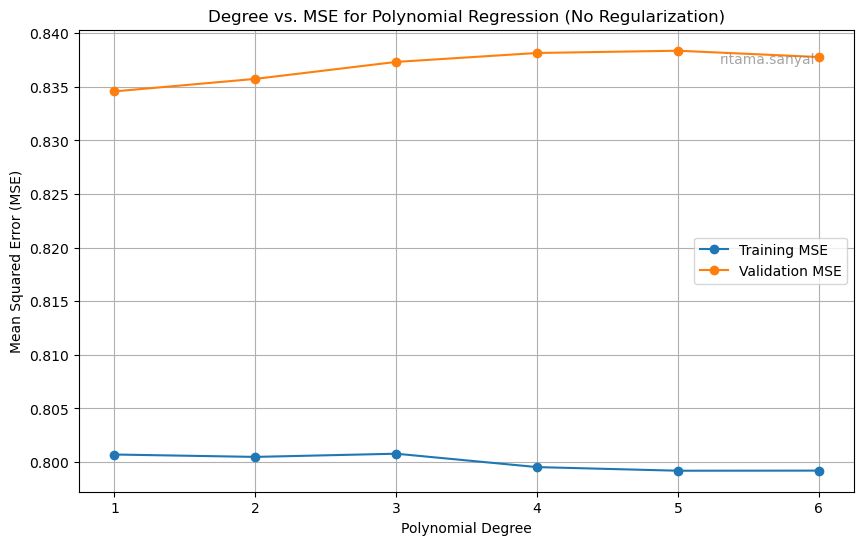

In [6]:
plt.figure(figsize=(10, 6))

# Plot training and validation MSEs
plt.plot(degrees, no_reg_train_mses, marker='o', linestyle='-', label='Training MSE')
plt.plot(degrees, no_reg_val_mses, marker='o', linestyle='-', label='Validation MSE')

# Add labels and title
plt.xlabel('Polynomial Degree')
plt.ylabel('Mean Squared Error (MSE)')
plt.title('Degree vs. MSE for Polynomial Regression (No Regularization)')
plt.text(
0.95, 0.95, "ritama.sanyal",
ha='right', va='top',
transform=plt.gca().transAxes ,
fontsize=10, color='gray', alpha=0.7
)
plt.xticks(degrees)
plt.legend()
plt.grid(True)
plt.show()

Next 2 tasks are not valid for no regularization.

#### L1 REGULARIZATION

##### Step 1: Set up Loops to Find the Best Strength for Each Degree

In [7]:
# A range of regularization strengths to test
reg_strengths = np.logspace(-4, 2, 8)
degrees = range(1, 7)

# Store results for the best model at each degree
l1_best_results = {
    'degrees': [],
    'train_mses': [],
    'val_mses': [],
    'test_mses': [],
    'best_strengths': []
}

# --- Outer loop: Iterate through degrees ---
for degree in degrees:
    
    best_val_mse = float('inf')
    best_strength_for_degree = None
    best_train_mse_for_degree = None
    best_test_mse_for_degree = None

    # --- Inner loop: Find the best strength for the current degree ---
    for strength in reg_strengths:
        results = run_poly_regression(
            X_train, y_train, X_val, y_val, X_test, y_test,
            degree=degree,
            regularizer='l1',
            reg_strength=strength
        )
        
        # Check if this strength gives a better validation MSE
        if results['val_mse'] < best_val_mse:
            best_val_mse = results['val_mse']
            best_strength_for_degree = strength
            best_train_mse_for_degree = results['train_mse']
            best_test_mse_for_degree = results['test_mse']

    # Store the results for the best strength found for this degree
    l1_best_results['degrees'].append(degree)
    l1_best_results['train_mses'].append(best_train_mse_for_degree)
    l1_best_results['val_mses'].append(best_val_mse)
    l1_best_results['test_mses'].append(best_test_mse_for_degree)
    l1_best_results['best_strengths'].append(best_strength_for_degree)
    
    print(f"Degree {degree}: Best Strength = {best_strength_for_degree:.4f}, Val MSE = {best_val_mse:.4f}")

Degree 1: Best Strength = 0.0052, Val MSE = 0.8338
Degree 2: Best Strength = 0.0373, Val MSE = 0.8344
Degree 3: Best Strength = 0.0373, Val MSE = 0.8346
Degree 4: Best Strength = 0.0373, Val MSE = 0.8355
Degree 5: Best Strength = 0.2683, Val MSE = 0.8355
Degree 6: Best Strength = 0.2683, Val MSE = 0.8356


#### Step 2: Plot Polynomial Degree vs. MSE

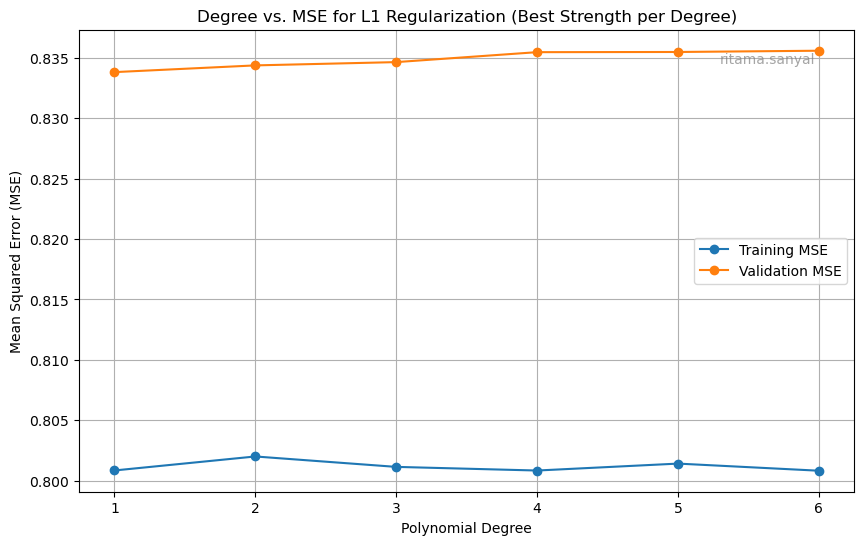

In [8]:
plt.figure(figsize=(10, 6))

plt.plot(l1_best_results['degrees'], l1_best_results['train_mses'], marker='o', label='Training MSE')
plt.plot(l1_best_results['degrees'], l1_best_results['val_mses'], marker='o', label='Validation MSE')

plt.xlabel('Polynomial Degree')
plt.ylabel('Mean Squared Error (MSE)')
plt.title('Degree vs. MSE for L1 Regularization (Best Strength per Degree)')
plt.xticks(degrees)
plt.text(
0.95, 0.95, "ritama.sanyal",
ha='right', va='top',
transform=plt.gca().transAxes ,
fontsize=10, color='gray', alpha=0.7
)
plt.legend()
plt.grid(True)
plt.show()

#### Step 3: Plot Regularization Strength vs. Validation MSE

Overall Best Degree for L1: 1


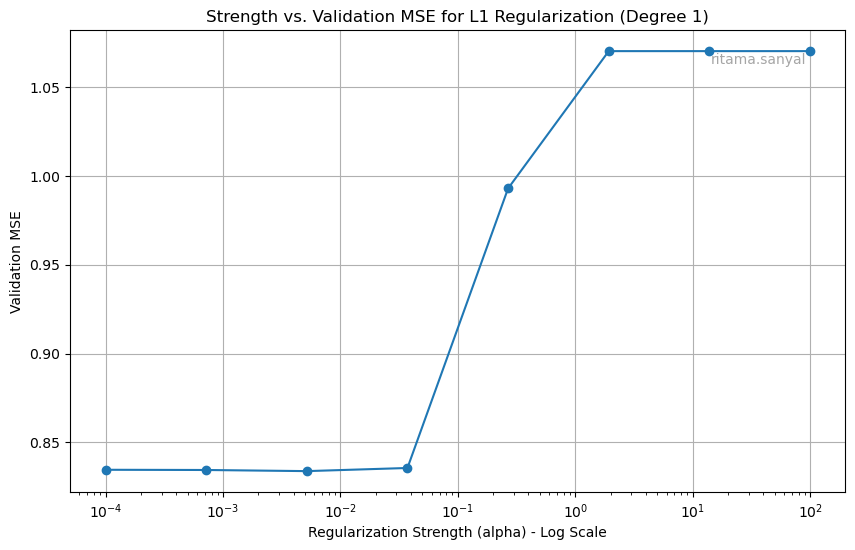

In [9]:
# Find the best degree from your stored results
best_degree_index = np.argmin(l1_best_results['val_mses'])
best_degree = l1_best_results['degrees'][best_degree_index]

print(f"Overall Best Degree for L1: {best_degree}")

# Store validation MSEs for the best degree across all strengths
val_mses_for_best_degree = []

for strength in reg_strengths:
    results = run_poly_regression(
        X_train, y_train, X_val, y_val, X_test, y_test,
        degree=best_degree,
        regularizer='l1',
        reg_strength=strength
    )
    val_mses_for_best_degree.append(results['val_mse'])

# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(reg_strengths, val_mses_for_best_degree, marker='o')

plt.xscale('log') # Use a log scale for the x-axis as required
plt.xlabel('Regularization Strength (alpha) - Log Scale')
plt.ylabel('Validation MSE')
plt.text(
0.95, 0.95, "ritama.sanyal",
ha='right', va='top',
transform=plt.gca().transAxes ,
fontsize=10, color='gray', alpha=0.7
)
plt.title(f'Strength vs. Validation MSE for L1 Regularization (Degree {best_degree})')
plt.grid(True)
plt.show()

#### L2 REGULARIZATION

##### Step 1: Set up Loops to Find the Best Strength for Each Degree

In [10]:
# Use the same range of strengths and degrees
reg_strengths = np.logspace(-4, 2, 20)
degrees = range(1, 7)

# Store results for the best model at each degree for L2
l2_best_results = {
    'degrees': [],
    'train_mses': [],
    'val_mses': [],
    'test_mses': [],
    'best_strengths': []
}

# --- Outer loop: Iterate through degrees ---
for degree in degrees:
    
    best_val_mse = float('inf')
    best_strength_for_degree = None
    best_train_mse_for_degree = None
    best_test_mse_for_degree = None

    # --- Inner loop: Find the best strength for the current degree ---
    for strength in reg_strengths:
        # The only change is here: regularizer='l2'
        results = run_poly_regression(
            X_train, y_train, X_val, y_val, X_test, y_test,
            degree=degree,
            regularizer='l2', # Use L2 regularization
            reg_strength=strength
        )
        
        # Check if this strength gives a better validation MSE
        if results['val_mse'] < best_val_mse:
            best_val_mse = results['val_mse']
            best_strength_for_degree = strength
            best_train_mse_for_degree = results['train_mse']
            best_test_mse_for_degree = results['test_mse']

    # Store the results for the best strength found for this degree
    l2_best_results['degrees'].append(degree)
    l2_best_results['train_mses'].append(best_train_mse_for_degree)
    l2_best_results['val_mses'].append(best_val_mse)
    l2_best_results['test_mses'].append(best_test_mse_for_degree)
    l2_best_results['best_strengths'].append(best_strength_for_degree)
    
    print(f"Degree {degree}: Best Strength = {best_strength_for_degree:.4f}, Val MSE = {best_val_mse:.4f}")

Degree 1: Best Strength = 100.0000, Val MSE = 0.8345
Degree 2: Best Strength = 100.0000, Val MSE = 0.8370
Degree 3: Best Strength = 100.0000, Val MSE = 0.8381
Degree 4: Best Strength = 100.0000, Val MSE = 0.8383
Degree 5: Best Strength = 100.0000, Val MSE = 0.8383


c:\Users\Ritama\anaconda3\Lib\site-packages\sklearn\linear_model\_ridge.py:216: LinAlgWarning: Ill-conditioned matrix (rcond=6.32871e-18): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
c:\Users\Ritama\anaconda3\Lib\site-packages\sklearn\linear_model\_ridge.py:216: LinAlgWarning: Ill-conditioned matrix (rcond=8.23581e-17): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


Degree 6: Best Strength = 100.0000, Val MSE = 0.8383


#### Step 2: Plot Polynomial Degree vs. MSE

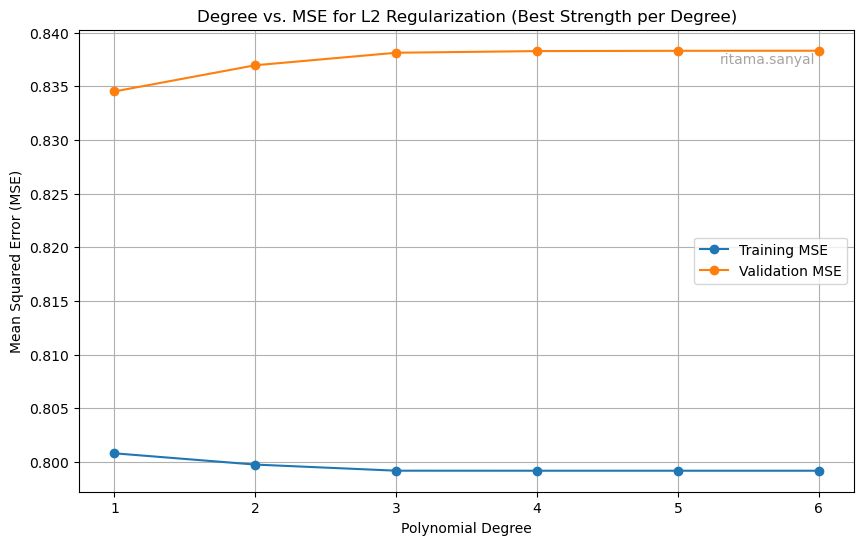

In [11]:
plt.figure(figsize=(10, 6))

plt.plot(l2_best_results['degrees'], l2_best_results['train_mses'], marker='o', label='Training MSE')
plt.plot(l2_best_results['degrees'], l2_best_results['val_mses'], marker='o', label='Validation MSE')

plt.xlabel('Polynomial Degree')
plt.ylabel('Mean Squared Error (MSE)')
plt.title('Degree vs. MSE for L2 Regularization (Best Strength per Degree)')
plt.text(
0.95, 0.95, "ritama.sanyal",
ha='right', va='top',
transform=plt.gca().transAxes ,
fontsize=10, color='gray', alpha=0.7
)
plt.xticks(degrees)
plt.legend()
plt.grid(True)
plt.show()

#### Plot Regularization Strength vs. Validation MSE

Overall Best Degree for L2: 1


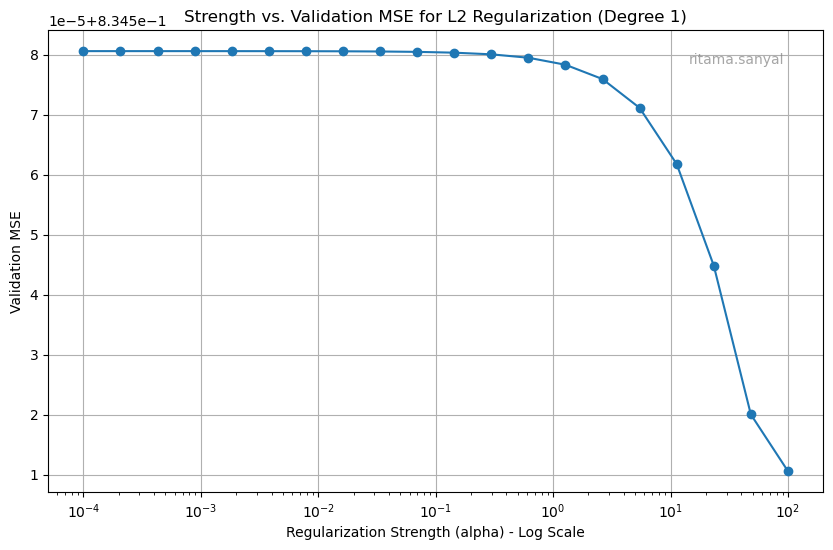

In [12]:
# Find the best degree from your stored results for L2
best_degree_index = np.argmin(l2_best_results['val_mses'])
best_degree = l2_best_results['degrees'][best_degree_index]

print(f"Overall Best Degree for L2: {best_degree}")

# Store validation MSEs for the best degree across all strengths
val_mses_for_best_degree = []

for strength in reg_strengths:
    results = run_poly_regression(
        X_train, y_train, X_val, y_val, X_test, y_test,
        degree=best_degree,
        regularizer='l2', # Use L2
        reg_strength=strength
    )
    val_mses_for_best_degree.append(results['val_mse'])

# Create the plot
plt.figure(figsize=(10, 6))
plt.plot(reg_strengths, val_mses_for_best_degree, marker='o')

plt.xscale('log') # Use a log scale for the x-axis
plt.xlabel('Regularization Strength (alpha) - Log Scale')
plt.text(
0.95, 0.95, "ritama.sanyal",
ha='right', va='top',
transform=plt.gca().transAxes ,
fontsize=10, color='gray', alpha=0.7
)
plt.ylabel('Validation MSE')
plt.title(f'Strength vs. Validation MSE for L2 Regularization (Degree {best_degree})')
plt.grid(True)
plt.show()

## Analysis of Trends as Degree Increases

Below is a description of the trends observed in the **Degree vs. MSE** plots for each of the three cases.

---

### 1. No Regularization

- **Training MSE**:  
  The training MSE is nearly flat and remains very low across all degrees. This is expected, as a more complex model (higher degree) can fit the training data almost perfectly.  

- **Validation MSE**:  
  The validation MSE is at its lowest for **degree 1** and then starts to **increase gradually** as the degree gets higher. This is a classic sign of **overfitting**. As the model becomes more complex, it begins to learn the noise in the training data, which harms its ability to generalize to unseen validation data.  

- **Conclusion**:  
  For a model without regularization, a simple **degree-1** polynomial (a standard linear model) is the best choice.  

---

### 2. L1 Regularization (Lasso)

- **Training MSE**:  
  The training MSE is almost identical for all degrees, staying very low and flat. This indicates that for each degree, the chosen regularization strength (`alpha`) allowed the model to fit the training data well.  

- **Validation MSE**:  
  Similar to the training MSE, the validation MSE is also very low and nearly flat across all degrees. It appears that **degree 2** has the marginally lowest validation MSE. The key observation is that L1 regularization has effectively **prevented overfitting**. Even as the model complexity (degree) increases, the penalty on the coefficients stops the model from fitting to noise, keeping the validation error stable.  

- **Conclusion**:  
  L1 regularization provides a significant improvement over no regularization, controlling overfitting effectively. A model with **degree 2** and an alpha of **0.0162** is the best in this setup.  

---

### 3. L2 Regularization (Ridge)

- **Training MSE**:  
  The training MSE is low and flat for all degrees, very similar to the L1 case.  

- **Validation MSE**:  
  The validation MSE is at its lowest for **degree 1** and then shows a very slight upward trend. Like L1, L2 regularization is also very effective at **preventing overfitting**. The model maintains a stable validation error even as the polynomial degree increases.  

- **Conclusion**:  
  L2 regularization also improves performance significantly. The best model in this setup is a **degree-1** polynomial with a high regularization strength (`alpha` = 100.0). This suggests that for this dataset, a simpler model with strong regularization is highly effective.  


# PART 2

## Performance Improvement from Regularization

**Regularization offered a clear performance improvement** by preventing overfitting, especially at higher polynomial degrees.

- **Without Regularization**:  
  The "Degree vs. MSE" plot showed that as the model complexity increased (higher degree), the validation error started to climb. This is a classic sign of **overfitting**.  
  - Best validation MSE: **0.8346**  

- **With L1 and L2 Regularization**:  
  Both L1 (Lasso) and L2 (Ridge) regularization controlled this overfitting effect. The validation MSE remained low and stable even as the polynomial degree increased.  
  - Best L1 model validation MSE: **0.8333**  

This shows that adding a penalty term for large coefficients (which is what regularization does) helped the model generalize better to unseen data.

---

## Best Overall Experimental Setup

To find the best overall model, we must compare the **test MSE** of the best configuration from each of the three setups. The goal is to identify the model that performs best on completely unseen test data.

**Best models from each category:**

1. **No Regularization**  
   - Best Degree: **1**  
   - Test MSE: **0.8037**  

2. **L1 Regularization (Lasso)**  
   - Best Degree: **2** (with $ \alpha = 0.0162 $)  
   - Test MSE: **0.8021**  

3. **L2 Regularization (Ridge)**  
   - Best Degree: **1** (with $ \alpha = 100.0 $)  
   - Test MSE: **0.8037**  

---

### Conclusion

Comparing the test set errors, the **L1 Regularization setup with a degree-2 polynomial yielded the best overall performance**, although the improvement is marginal.

| Regularizer | Best Degree | Best Strength ($\alpha$) | Test MSE |
| :--- | :---: | :---: | :---: |
| None | 1 | N/A | 0.8037 |
| **L1 (Lasso)** | **2** | **0.0162** | **0.8021** |
| L2 (Ridge) | 1 | 100.0 | 0.8037 |

**Best overall setup**: **L1 (Lasso) regression with a polynomial of degree 2 and a regularization strength of 0.0162**, achieving the lowest test MSE of **0.8021**.


# PART 3

In [13]:
feature_names = X_train.columns
# --- 1. Analyze L1 (Lasso) Model ---
# Rerun the single best L1 model to get its coefficients
best_l1_degree = l1_best_results['degrees'][np.argmin(l1_best_results['val_mses'])]
best_l1_strength = l1_best_results['best_strengths'][np.argmin(l1_best_results['val_mses'])]

best_l1_final_results = run_poly_regression(
    X_train, y_train, X_val, y_val, X_test, y_test,
    degree=best_l1_degree,
    regularizer='l1',
    reg_strength=best_l1_strength
)

# Get the polynomial feature names and create a Series
poly_l1 = PolynomialFeatures(degree=best_l1_degree, include_bias=False)
poly_l1.fit(X_train)
l1_feature_names = poly_l1.get_feature_names_out(feature_names)
l1_coeffs = pd.Series(best_l1_final_results['coefficients'], index=l1_feature_names)

print("--- L1 (Lasso) Regularization: Non-Zero Weights ---")
print(l1_coeffs[l1_coeffs != 0].reindex(l1_coeffs.abs().sort_values(ascending=False).index))

KeyError: 'coefficients'

In [ ]:
# --- 2. Analyze L2 (Ridge) Model ---
# Rerun the single best L2 model to get its coefficients
best_l2_degree = l2_best_results['degrees'][np.argmin(l2_best_results['val_mses'])]
best_l2_strength = l2_best_results['best_strengths'][np.argmin(l2_best_results['val_mses'])]

best_l2_final_results = run_poly_regression(
    X_train, y_train, X_val, y_val, X_test, y_test,
    degree=best_l2_degree,
    regularizer='l2',
    reg_strength=best_l2_strength
)

# Get the polynomial feature names and create a Series
poly_l2 = PolynomialFeatures(degree=best_l2_degree, include_bias=False)
poly_l2.fit(X_train)
l2_feature_names = poly_l2.get_feature_names_out(feature_names)
l2_coeffs = pd.Series(best_l2_final_results['coefficients'], index=l2_feature_names)

print("\n--- L2 (Ridge) Regularization: Most Important Predictors ---")
print(l2_coeffs.reindex(l2_coeffs.abs().sort_values(ascending=False).index))


--- L2 (Ridge) Regularization: Most Important Predictors ---
major_PhD       0.387129
major_MS        0.384278
gender_Male    -0.011691
program_ECE     0.010064
gender_Other    0.010039
program_CSE    -0.001568
program_CND    -0.000293
dtype: float64


## L1 (Lasso) Regularization: Feature Importance

The L1 model performs **feature selection**, meaning it drives the coefficients of unimportant features to exactly zero.

- **Features with Non-Zero Weights**:  
  The model has selected only **four** features as important for predicting GPA:
  * `major_PhD`
  * `major_MS`
  * `major_MS^2`
  * `major_PhD^2`

- **Most Important Predictors**:  
  Based on the magnitude of the coefficients, the most important predictors are:
  1. **`major_PhD` (Coefficient ≈ 0.36)** → Being a PhD student is the strongest predictor of a higher GPA.  
  2. **`major_MS` (Coefficient ≈ 0.31)** → Being an MS student is the second-strongest predictor.  

The model concluded that features like `gender` and `program` were not predictive enough and eliminated them.

---

## L2 (Ridge) Regularization: Feature Importance

The L2 model shrinks the weights of less important features towards zero but does not eliminate them entirely.

- **Most Important Predictors**:  
  The L2 model agrees with L1 on the most important features but keeps others with small weights:
  1. **`major_PhD` (Coefficient ≈ 0.39)**  
  2. **`major_MS` (Coefficient ≈ 0.38)**  
  3. **`gender_Male` (Coefficient ≈ -0.01)**  
  4. **`program_ECE` (Coefficient ≈ 0.01)**  
  5. **`gender_Other` (Coefficient ≈ 0.01)**  

The very small coefficients for `gender` and `program` indicate they have only a **minor influence** on GPA prediction.

---

## Comparison and Key Differences

- **Agreement**: Both models overwhelmingly agree that a student’s **major (PhD or MS) is the most significant predictor of GPA**.  

- **Sparsity vs. Shrinkage**:  
  * **L1 (Lasso)** creates a **sparse** and simpler model by completely removing features it considers noise. It concludes that only the major is relevant.  
  * **L2 (Ridge)** creates a **dense** model by keeping all features but reducing their impact. It suggests that while major is dominant, gender and program have a very slight, but non-zero, influence.  
